# diffsvg in 10 minutes

diffsvg compares how genes change with the distance to an anchor (a region, a cell type or a set of points) between two conditions, with biological replicates as the unit of comparison. The page runs the whole workflow on the Legnini et al. organoids: 88 genes, 4 organoids with SHH and 4 controls, and the cells with the highest SHH expression as the anchor.

Install diffsvg with `pip install diffsvg`. The example also uses squidpy, for the distances.

**Your own data** needs coordinates in `obsm["spatial"]`, a log-normalised layer, and `obs` columns for the section, the condition, the replicate (e.g. donor) and a group that marks the anchor cells (e.g. a cell type). Here the anchor group is built from SHH expression; usually it is an existing annotation, e.g. `cluster_key="cell_type", groups="Tumor"`, and then `anchor="Tumor"` in `bin_obs`.

In [1]:
import numpy as np
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

adata = dvg.datasets.legnini23()  # downloads about 90 MB once

## 1. Distance to the anchor

Every cell gets its distance to the nearest anchor cell of its own section, scaled to 0 to 1. `var_by_distance` stores it in `adata.obsm["design_matrix"]`, in a column named after the anchor group, together with the condition and the replicate of every cell. The replicate column has to be a string, hence the last line.

In [2]:
shh = sc.get.obs_df(adata, "SHH")["SHH"].to_numpy()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(
    adata, cluster_key="SHH+", groups="True", library_key="sample", covariates=["condition", "organoid"]
)
adata.obsm["design_matrix"]["organoid"] = adata.obsm["design_matrix"]["organoid"].astype(str)

## 2. Bin and fit

`bin_obs` averages each gene along the distance, per organoid. `sample="organoid"` makes the organoid the replicate, so the conditions are compared against the variation between organoids, not between cells. `fit_model` then tests every gene; `test="parallel"` asks whether the two condition curves differ in shape.

In [3]:
dvg.pp.bin_obs(adata, anchor="True", condition="condition", layer="log1p_norm", sample="organoid")
dvg.tl.fit_model(adata, dvg.tl.setup_model(adata), test="parallel")

stats = adata.varm["dsvg_stats"].sort_values("parallel_pval")
stats[["shape_diff", "slope_diff", "parallel_pval", "parallel_pval_adj"]].head()

,shape_diff,slope_diff,parallel_pval,parallel_pval_adj
FOXA2,0.325483,0.198719,9.390106e-07,0.000083
HHIP,1.417356,0.976790,1.204555e-04,0.005300
PAX7,1.269618,-0.996571,2.614018e-04,0.007668
NEUROG2,1.017012,0.573022,5.412339e-04,0.010921
GLI1,1.231383,1.036409,6.205072e-04,0.010921


## 3. Look at the results

`shape_diff` measures how much the gap between the two curves changes along the distance, and `parallel_pval_adj` below 0.05 marks a hit. In the volcano plot, blue genes have an SHH minus Ctrl difference that increases with the distance from the anchor, and red genes one that decreases.

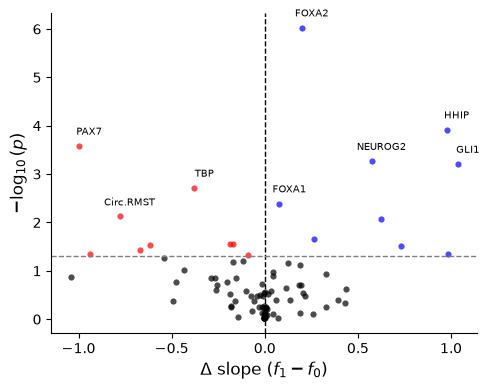

In [4]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=8, figsize=(5, 4));

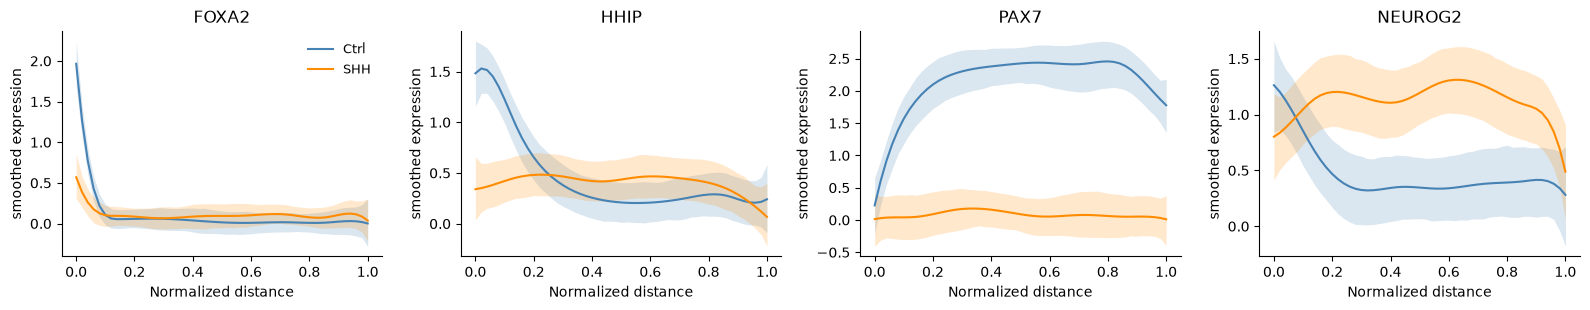

In [5]:
dvg.pl.plot_prediction_curve(adata, gene=list(stats.index[:4]));

In the controls the anchor cells are a small domain with endogenous SHH, while in the SHH organoids SHH is expressed widely, so FOXA2 and HHIP peak near the anchor only in the controls; the replicates guide discusses this.

## 4. Gene sets

With few replicates, single genes need strong effects to pass FDR. `gene_set_test` asks whether a set of genes changes together.

In [6]:
shh_targets = ["GLI1", "PTCH1", "HHIP", "FOXA2", "NKX6.1", "NKX6.2", "OLIG2"]
dvg.tl.gene_set_test(dvg.tl.setup_model(adata), {"SHH targets": shh_targets})

,summary,set,size,mean_t,pval_up,pval_down,pval_mixed,pval,pval_adj
0,level,SHH targets,7,4.095945,0.0002,0.9999,0.0004,0.0004,0.0004
1,slope,SHH targets,7,2.719620,0.0039,0.9962,0.0072,0.0078,0.0078


Both rows are significant with a positive `mean_t`: the SHH targets are higher in the SHH organoids on average (level), and the SHH minus Ctrl difference increases with distance (slope), because the controls have their peak near the anchor.

## Next

- [Comparing conditions with replicates](replicates_tutorial.ipynb) explains the shape, level and slope tests, how to read the gene-set table, and how to check the tests on a random split.
- [Choosing settings and clustering curves](settings_and_clustering.ipynb) checks the model settings and groups genes by their curves.
- [Data without replicates](without_replicates.ipynb) covers a single sample.